[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ayeshaalamexe/cs320-yolov1/blob/main/paper_lead/paper_lead_complete.ipynb)

In [47]:
!pip install -q torchmetrics pycocotools

import os, time, random
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.optim as optim, torchvision
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import xml.etree.ElementTree as ET
from PIL import Image, ImageEnhance
from torch.utils.data import Dataset, DataLoader
from torchvision.ops import batched_nms
from torchmetrics.detection import MeanAveragePrecision

print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0))

# Drive mount (checkpoints yahan save hongi)
from google.colab import drive
drive.mount('/content/drive')
CKPT_DIR = '/content/drive/MyDrive/yolo_project/checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)

# seed fix
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# constants
IMG_SIZE = 448
S, B = 7, 2        # grid 7x7, har cell mein 2 boxes
C = 1              # Penn-Fudan mein sirf 1 class (pedestrian)

GPU: True Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [48]:
# ---- Step 2: Penn-Fudan download ----
!wget -q https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip -O /content/PennFudanPed.zip
!unzip -q -o /content/PennFudanPed.zip -d /content/
ROOT = '/content/PennFudanPed'
print(os.listdir(ROOT))

['added-object-list.txt', 'Annotation', 'readme.txt', 'PedMasks', 'PNGImages']


In [49]:
# ---- Step 3: target banana (image ke boxes -> 7x7 grid) ----
def make_target(boxes, labels, S=7, C=1):
    # boxes: (x1, y1, x2, y2), 0 se 1 ke beech
    # target ka size: S x S x (5 + C) = [x, y, w, h, obj, class one-hot]
    t = torch.zeros(S, S, 5 + C)
    for (x1, y1, x2, y2), c in zip(boxes, labels):
        xc, yc, w, h = (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1
        j = min(int(xc * S), S - 1)      # column
        i = min(int(yc * S), S - 1)      # row
        if t[i, j, 4] == 1:              # cell pehle se bhara hai, skip
            continue
        t[i, j, 0] = xc * S - j          # x cell ke andar
        t[i, j, 1] = yc * S - i          # y cell ke andar
        t[i, j, 2] = w
        t[i, j, 3] = h
        t[i, j, 4] = 1                   # object hai
        t[i, j, 5 + int(c)] = 1          # class
    return t

In [50]:
# ---- Step 4: Penn-Fudan dataset ----
class PennFudanDataset(Dataset):
    def __init__(self, root, files, augment=False, img_size=448, S=7, C=1):
        self.root, self.files, self.augment = root, files, augment
        self.img_size, self.S, self.C = img_size, S, C
        self.boxes = []
        for f in files:
            # har pedestrian ka box mask se nikalte hain
            mask = np.array(Image.open(f'{root}/PedMasks/{f[:-4]}_mask.png'))
            H, W = mask.shape
            b = []
            for k in np.unique(mask)[1:]:          # 0 = background
                ys, xs = np.where(mask == k)
                b.append([xs.min() / W, ys.min() / H, (xs.max() + 1) / W, (ys.max() + 1) / H])
            self.boxes.append(np.array(b, dtype=np.float32))

    def __len__(self):
        return len(self.files)

    def load_image(self, i):
        return Image.open(f'{self.root}/PNGImages/{self.files[i]}').convert('RGB')

    def image(self, i):
        # bina augmentation wali image (evaluation ke liye)
        img = self.load_image(i).resize((self.img_size, self.img_size))
        return torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0

    def ground_truth(self, i):
        boxes = torch.tensor(self.boxes[i])
        return boxes, torch.zeros(len(boxes), dtype=torch.long), torch.zeros(len(boxes), dtype=torch.bool)

    def __getitem__(self, i):
        img = self.load_image(i)
        boxes = self.boxes[i].copy()
        if self.augment:
            if random.random() < 0.5:                       # horizontal flip
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
                boxes[:, [0, 2]] = 1 - boxes[:, [2, 0]]
            img = ImageEnhance.Brightness(img).enhance(random.uniform(0.7, 1.3))   # brightness
        img = img.resize((self.img_size, self.img_size))
        x = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
        labels = np.zeros(len(boxes), dtype=int)
        return x, make_target(boxes, labels, self.S, self.C)

In [51]:
def make_target(boxes, labels, S=7, C=1):
    t = torch.zeros(S, S, 5 + C)
    for (x1, y1, x2, y2), c in zip(boxes, labels):
        x1, y1, x2, y2 = float(x1), float(y1), float(x2), float(y2)   # numpy.float32 -> python float
        xc, yc, w, h = (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1
        j = min(int(xc * S), S - 1)
        i = min(int(yc * S), S - 1)
        if t[i, j, 4] == 1:
            continue
        t[i, j, 0] = xc * S - j
        t[i, j, 1] = yc * S - i
        t[i, j, 2] = w
        t[i, j, 3] = h
        t[i, j, 4] = 1
        t[i, j, 5 + int(c)] = 1
    return t

print("make_target updated")

make_target updated


Train / Val / Test: 119 25 26
Image batch: torch.Size([8, 3, 448, 448]) torch.float32 | min 0.0 | max 1.0
Target batch: torch.Size([8, 7, 7, 6])


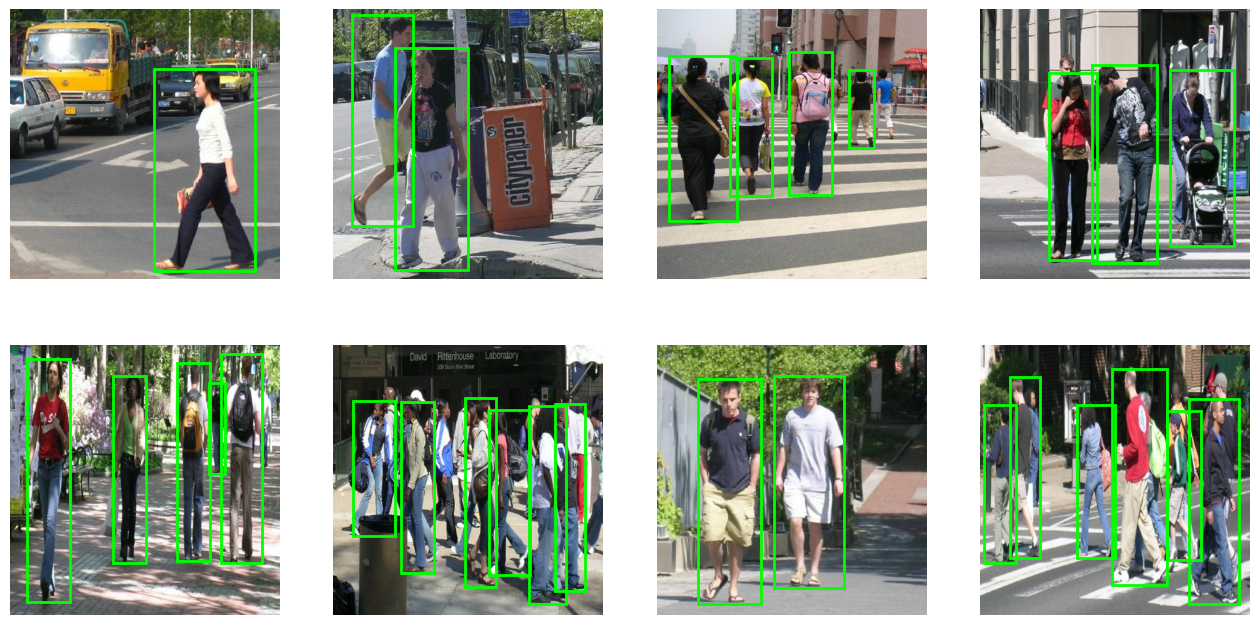

In [52]:
# ---- Step 5: split (team ki split_manifest.csv se) aur loaders ----
!rm -rf /content/repo
!git clone -q https://github.com/ayeshaalamexe/cs320-yolov1.git /content/repo
man = pd.read_csv('/content/repo/PennFudanYOLO/split_manifest.csv')

AUG = False     # baseline ke liye False
train_set = PennFudanDataset(ROOT, list(man[man.split == 'train'].filename), augment=AUG, S=S, C=C)
val_set   = PennFudanDataset(ROOT, list(man[man.split == 'val'].filename), S=S, C=C)
test_set  = PennFudanDataset(ROOT, list(man[man.split == 'test'].filename), S=S, C=C)

train_loader = DataLoader(train_set, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_set, batch_size=8, shuffle=False)

xb, tb = next(iter(train_loader))
print("Train / Val / Test:", len(train_set), len(val_set), len(test_set))
print("Image batch:", xb.shape, xb.dtype, "| min", xb.min().item(), "| max", xb.max().item())
print("Target batch:", tb.shape)

# batch ki images aur boxes plot
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, img, t in zip(axes.flat, xb, tb):
    ax.imshow(img.permute(1, 2, 0))
    for i in range(S):
        for j in range(S):
            if t[i, j, 4] == 1:
                xc, yc = (j + t[i, j, 0]) / S, (i + t[i, j, 1]) / S
                w, h = t[i, j, 2], t[i, j, 3]
                ax.add_patch(patches.Rectangle(((xc - w / 2) * IMG_SIZE, (yc - h / 2) * IMG_SIZE),
                             w * IMG_SIZE, h * IMG_SIZE, linewidth=2, edgecolor='lime', facecolor='none'))
    ax.axis('off')
plt.show()

In [53]:
# ---- Step 6: YOLOv1 model ----
class YOLOv1(nn.Module):
    def __init__(self, S=7, B=2, C=1):
        super().__init__()
        self.S, self.B, self.C = S, B, C
        resnet = torchvision.models.resnet34(weights=torchvision.models.ResNet34_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])   # out: 512 x 14 x 14
        self.head = nn.Sequential(
            nn.Conv2d(512, 1024, 3, stride=2, padding=1),   # 14x14 -> 7x7
            nn.BatchNorm2d(1024),
            nn.LeakyReLU(0.1),
            nn.Conv2d(1024, 1024, 3, padding=1),
            nn.BatchNorm2d(1024),
            nn.LeakyReLU(0.1),
            nn.Flatten(),
            nn.Linear(7 * 7 * 1024, 4096),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.5),
            nn.Linear(4096, S * S * (B * 5 + C)),
        )
        # ImageNet ka mean aur std (backbone ImageNet par train hua tha)
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = (x - self.mean) / self.std       # normalization
        x = self.backbone(x)
        x = self.head(x)
        return x.view(-1, self.S, self.S, self.B * 5 + self.C)

model = YOLOv1(S, B, C).cuda()
print("Output shape:", model(torch.rand(2, 3, IMG_SIZE, IMG_SIZE).cuda()).shape)

Output shape: torch.Size([2, 7, 7, 11])


In [54]:
# ---- Step 7: loss ----
def cell_iou(p, t, S=7):
    # p, t: (..., 4) = x, y, w, h. x,y cell ke andar, w,h image ke relative
    pw, ph = p[..., 2].abs() * S, p[..., 3].abs() * S
    tw, th = t[..., 2] * S, t[..., 3] * S
    p1x, p2x = p[..., 0] - pw / 2, p[..., 0] + pw / 2
    p1y, p2y = p[..., 1] - ph / 2, p[..., 1] + ph / 2
    t1x, t2x = t[..., 0] - tw / 2, t[..., 0] + tw / 2
    t1y, t2y = t[..., 1] - th / 2, t[..., 1] + th / 2
    iw = (torch.min(p2x, t2x) - torch.max(p1x, t1x)).clamp(min=0)
    ih = (torch.min(p2y, t2y) - torch.max(p1y, t1y)).clamp(min=0)
    inter = iw * ih
    union = pw * ph + tw * th - inter + 1e-6
    return inter / union

class YOLOLoss(nn.Module):
    def __init__(self, S=7, B=2, C=1, l_coord=5.0, l_noobj=0.5):
        super().__init__()
        self.S, self.B, self.C = S, B, C
        self.l_coord, self.l_noobj = l_coord, l_noobj

    def forward(self, pred, target):
        N = pred.shape[0]
        obj = target[..., 4]                          # N,S,S
        noobj = 1 - obj
        b1, b2 = pred[..., 0:5], pred[..., 5:10]
        iou1 = cell_iou(b1[..., :4], target[..., :4], self.S)
        iou2 = cell_iou(b2[..., :4], target[..., :4], self.S)
        r2 = (iou2 > iou1).float().unsqueeze(-1)      # 1 => box 2 zimmedar
        resp = r2 * b2 + (1 - r2) * b1                # zimmedar box
        best_iou = torch.max(iou1, iou2).detach()

        # 1) x, y
        l_xy = (obj.unsqueeze(-1) * (resp[..., 0:2] - target[..., 0:2]) ** 2).sum()
        # 2) w, h (sqrt ke sath)
        pwh = torch.sign(resp[..., 2:4]) * torch.sqrt(resp[..., 2:4].abs() + 1e-6)
        twh = torch.sqrt(target[..., 2:4])
        l_wh = (obj.unsqueeze(-1) * (pwh - twh) ** 2).sum()
        # 3) confidence (object wale cells)
        l_obj = (obj * (resp[..., 4] - best_iou) ** 2).sum()
        # 4) confidence (khali cells, dono boxes)
        l_noobj = (noobj * (b1[..., 4] ** 2 + b2[..., 4] ** 2)).sum()
        # 5) class
        l_cls = (obj.unsqueeze(-1) * (pred[..., 10:] - target[..., 5:]) ** 2).sum()

        total = (self.l_coord * (l_xy + l_wh) + l_obj + self.l_noobj * l_noobj + l_cls) / N
        parts = dict(xy=l_xy.item() / N, wh=l_wh.item() / N, obj=l_obj.item() / N,
                     noobj=l_noobj.item() / N, cls=l_cls.item() / N)
        return total, parts

criterion = YOLOLoss(S, B, C)
print("Loss ready")

Loss ready


In [55]:
# ---- Step 8: detection (decode + NMS) aur mAP ----
def detect(pred, S=7, B=2, C=1, conf_thr=0.01, nms_iou=0.5):
    # pred: ek image ka output (S, S, B*5+C). Wapas: boxes (0-1), scores, labels
    pred = pred.float().cpu()
    cls_prob = pred[..., B * 5:]
    ys, xs = torch.meshgrid(torch.arange(S), torch.arange(S), indexing='ij')
    boxes, scores, labels = [], [], []
    for b in range(B):
        x, y, w, h, conf = [pred[..., b * 5 + k] for k in range(5)]
        cx, cy = (xs + x) / S, (ys + y) / S                 # image ke relative center
        w, h = w.abs(), h.abs()
        box = torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], dim=-1).reshape(-1, 4)
        sc = (conf.unsqueeze(-1) * cls_prob).reshape(-1, C)  # score = confidence x class prob
        for c in range(C):
            keep = sc[:, c] > conf_thr
            boxes.append(box[keep])
            scores.append(sc[keep, c])
            labels.append(torch.full((int(keep.sum()),), c, dtype=torch.long))
    boxes = torch.cat(boxes).clamp(0, 1)
    scores = torch.cat(scores)
    labels = torch.cat(labels)
    keep = batched_nms(boxes, scores, labels, nms_iou)      # NMS
    return boxes[keep], scores[keep], labels[keep]


def evaluate(model, dataset, S=7, B=2, C=1, conf_thr=0.01, nms_iou=0.5, batch_size=16):
    # mAP@0.5 (torchmetrics) aur speed. Difficult objects ko iscrowd bana kar ignore karte hain.
    model.eval()
    metric = MeanAveragePrecision(box_format='xyxy', iou_thresholds=[0.5], class_metrics=True)
    model_time, n = 0.0, len(dataset)
    for start in range(0, n, batch_size):
        idxs = list(range(start, min(n, start + batch_size)))
        x = torch.stack([dataset.image(i) for i in idxs]).cuda()
        torch.cuda.synchronize()
        t0 = time.time()
        with torch.no_grad():
            out = model(x)
        torch.cuda.synchronize()
        model_time += time.time() - t0
        preds, gts = [], []
        for k, i in enumerate(idxs):
            boxes, scores, labels = detect(out[k], S, B, C, conf_thr, nms_iou)
            preds.append(dict(boxes=boxes * IMG_SIZE, scores=scores, labels=labels))
            gb, gl, gd = dataset.ground_truth(i)
            gts.append(dict(boxes=gb * IMG_SIZE, labels=gl, iscrowd=gd.int()))
        metric.update(preds, gts)
    res = metric.compute()
    ms = 1000 * model_time / n
    return res, ms

In [18]:
# ---- Step 9: shape check (har layer ke baad) ----
out_size = S * S * (B * 5 + C)
expected_backbone = [(64, 224, 224), (64, 224, 224), (64, 224, 224), (64, 112, 112),
                     (64, 112, 112), (128, 56, 56), (256, 28, 28), (512, 14, 14)]
expected_head = [(1024, 7, 7), (1024, 7, 7), (1024, 7, 7), (1024, 7, 7), (1024, 7, 7), (1024, 7, 7),
                 (7 * 7 * 1024,), (4096,), (4096,), (4096,), (out_size,)]

model.eval()
x = torch.rand(2, 3, IMG_SIZE, IMG_SIZE).cuda()
with torch.no_grad():
    x = (x - model.mean) / model.std
    for layer, exp in zip(model.backbone, expected_backbone):
        x = layer(x)
        print(layer.__class__.__name__, tuple(x.shape[1:]), 'expected', exp)
        assert tuple(x.shape[1:]) == exp
    for layer, exp in zip(model.head, expected_head):
        x = layer(x)
        print(layer.__class__.__name__, tuple(x.shape[1:]), 'expected', exp)
        assert tuple(x.shape[1:]) == exp
print("Saari shapes theek hain")

Conv2d (64, 224, 224) expected (64, 224, 224)
BatchNorm2d (64, 224, 224) expected (64, 224, 224)
ReLU (64, 224, 224) expected (64, 224, 224)
MaxPool2d (64, 112, 112) expected (64, 112, 112)
Sequential (64, 112, 112) expected (64, 112, 112)
Sequential (128, 56, 56) expected (128, 56, 56)
Sequential (256, 28, 28) expected (256, 28, 28)
Sequential (512, 14, 14) expected (512, 14, 14)
Conv2d (1024, 7, 7) expected (1024, 7, 7)
BatchNorm2d (1024, 7, 7) expected (1024, 7, 7)
LeakyReLU (1024, 7, 7) expected (1024, 7, 7)
Conv2d (1024, 7, 7) expected (1024, 7, 7)
BatchNorm2d (1024, 7, 7) expected (1024, 7, 7)
LeakyReLU (1024, 7, 7) expected (1024, 7, 7)
Flatten (50176,) expected (50176,)
Linear (4096,) expected (4096,)
LeakyReLU (4096,) expected (4096,)
Dropout (4096,) expected (4096,)
Linear (539,) expected (539,)
Saari shapes theek hain


In [19]:
# ---- Step 10: parameter count (haath se vs PyTorch) ----
def count(m):
    return sum(p.numel() for p in m.parameters())

# ResNet block: 2 conv (64->64, 3x3, bias nahi) + 2 BatchNorm(64)
block_hand = 2 * (64 * 64 * 3 * 3) + 2 * (2 * 64)
# head conv 1: 512 -> 1024, 3x3, bias ke sath
conv_hand = 512 * 1024 * 3 * 3 + 1024
# head linear 1: 50176 -> 4096
fc_hand = 7 * 7 * 1024 * 4096 + 4096

print("ResNet block  | haath:", block_hand, "| PyTorch:", count(model.backbone[4][0]))
print("Head conv 1   | haath:", conv_hand, "| PyTorch:", count(model.head[0]))
print("Head linear 1 | haath:", fc_hand, "| PyTorch:", count(model.head[7]))
assert block_hand == count(model.backbone[4][0])
assert conv_hand == count(model.head[0])
assert fc_hand == count(model.head[7])
print("Total parameters:", count(model))

ResNet block  | haath: 73984 | PyTorch: 73984
Head conv 1   | haath: 4719616 | PyTorch: 4719616
Head linear 1 | haath: 205524992 | PyTorch: 205524992
Total parameters: 243179867


Pehla loss: 34.508270263671875 {'xy': 1.981, 'wh': 3.568, 'obj': 0.445, 'noobj': 5.261, 'cls': 3.687}
Zero gradient wali layers: koi nahi
Train boxes: 295 | target mein bache: 284 | gir gaye: 11
step 0 | loss 32.7873
step 40 | loss 1.8309
step 80 | loss 0.1717
step 120 | loss 1.4613
step 160 | loss 0.6137
step 199 | loss 0.2651


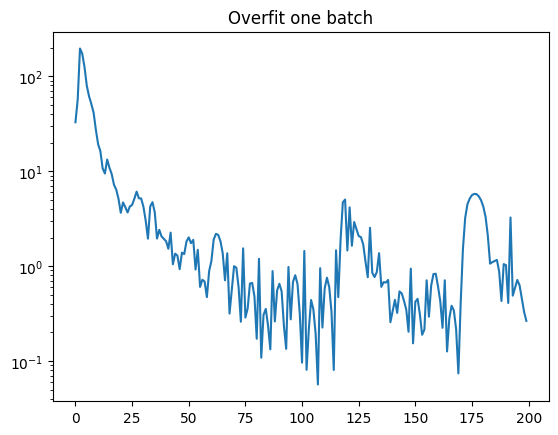

In [20]:
# ---- Step 11: sanity checks (pehla loss, gradients, overfit one batch) ----
xb, tb = next(iter(train_loader))
xb, tb = xb.cuda(), tb.cuda()

# pehla loss
model.train()
with torch.no_grad():
    loss, parts = criterion(model(xb), tb)
print("Pehla loss:", loss.item(), {k: round(v, 3) for k, v in parts.items()})

# har layer ko gradient mil raha hai?
loss, _ = criterion(model(xb), tb)
model.zero_grad()
loss.backward()
dead = []
for name, p in model.named_parameters():
    if name.endswith('weight') and p.dim() > 1:          # sirf conv aur linear weights
        g = p.grad.norm().item() if p.grad is not None else 0.0
        if g == 0:
            dead.append(name)
print("Zero gradient wali layers:", dead if dead else "koi nahi")

# kitne boxes ek cell ke masle se gir gaye (limitation ke liye)
total = sum(len(b) for b in train_set.boxes)
kept = sum(int(train_set[i][1][..., 4].sum()) for i in range(len(train_set)))
print("Train boxes:", total, "| target mein bache:", kept, "| gir gaye:", total - kept)

# overfit one batch (dropout band, nayi model)
test_model = YOLOv1(S, B, C).cuda()
for m in test_model.modules():
    if isinstance(m, nn.Dropout):
        m.p = 0.0
opt = optim.Adam(test_model.parameters(), lr=1e-4)
test_model.train()
history = []
for step in range(200):
    loss, _ = criterion(test_model(xb), tb)
    opt.zero_grad()
    loss.backward()
    opt.step()
    history.append(loss.item())
    if step % 40 == 0 or step == 199:
        print("step", step, "| loss", round(loss.item(), 4))
plt.plot(history)
plt.yscale('log')
plt.title("Overfit one batch")
plt.show()
del test_model

In [56]:
# ---- Step 12: training function ----
def train(model, train_loader, val_loader, name, epochs=30, lr=1e-4,
          freeze_epochs=3, warmup_steps=100, S=7, B=2, C=1, resume=True):
    criterion = YOLOLoss(S, B, C)
    opt = optim.Adam(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler('cuda')
    last_path = f'{CKPT_DIR}/{name}_last.pt'
    best_path = f'{CKPT_DIR}/{name}_best.pt'
    train_hist, val_hist, best, start = [], [], 1e9, 0

    # checkpoint ho to wahin se shuru
    if resume and os.path.exists(last_path):
        ck = torch.load(last_path)
        model.load_state_dict(ck['model'])
        opt.load_state_dict(ck['opt'])
        train_hist, val_hist = ck['train_hist'], ck['val_hist']
        best, start = ck['best'], ck['epoch'] + 1
        print("resume: epoch", start, "se")

    step = start * len(train_loader)

    for ep in range(start, epochs):
        t0 = time.time()

        # pehle epochs mein backbone freeze
        freeze = ep < freeze_epochs
        for p in model.backbone.parameters():
            p.requires_grad = not freeze
        model.train()
        if freeze:
            model.backbone.eval()

        # ---- train ----
        total, n = 0.0, 0
        for xb, tb in train_loader:
            xb, tb = xb.cuda(), tb.cuda()
            if step < warmup_steps:                      # warmup: lr dheere dheere barhta hai
                for g in opt.param_groups:
                    g['lr'] = lr * (step + 1) / warmup_steps
            with torch.autocast('cuda', dtype=torch.float16):
                pred = model(xb)
            loss, _ = criterion(pred.float(), tb)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 10.0)   # bara gradient kaat do
            scaler.step(opt)
            scaler.update()
            step += 1
            total += loss.item() * xb.size(0)
            n += xb.size(0)
        tr = total / n

        # ---- validation ----
        va = float('nan')
        if val_loader is not None:
            model.eval()
            total, n = 0.0, 0
            with torch.no_grad():
                for xb, tb in val_loader:
                    with torch.autocast('cuda', dtype=torch.float16):
                        pred = model(xb.cuda())
                    loss, _ = criterion(pred.float(), tb.cuda())
                    total += loss.item() * xb.size(0)
                    n += xb.size(0)
            va = total / n
            if va < best:
                best = va
                torch.save({'model': model.state_dict()}, best_path)

        train_hist.append(tr)
        val_hist.append(va)
        torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'epoch': ep,
                    'train_hist': train_hist, 'val_hist': val_hist, 'best': best}, last_path)
        print(f"epoch {ep+1:2d}/{epochs} | train {tr:.3f} | val {va:.3f} | {time.time()-t0:.0f}s")

    return train_hist, val_hist

epoch  1/30 | train 20.844 | val 5.586 | 33s
epoch  2/30 | train 12.378 | val 5.950 | 34s
epoch  3/30 | train 13.884 | val 6.383 | 28s
epoch  4/30 | train 10.029 | val 6.287 | 53s
epoch  5/30 | train 10.356 | val 5.016 | 115s
epoch  6/30 | train 11.168 | val 5.742 | 39s
epoch  7/30 | train 10.372 | val 7.746 | 31s
epoch  8/30 | train 11.241 | val 63.964 | 45s
epoch  9/30 | train 11.549 | val 367.273 | 44s
epoch 10/30 | train 8.990 | val 11.504 | 29s
epoch 11/30 | train 6.251 | val 20.512 | 31s
epoch 12/30 | train 5.607 | val 4.714 | 90s
epoch 13/30 | train 9.281 | val 71.559 | 32s
epoch 14/30 | train 9.929 | val 18.622 | 27s
epoch 15/30 | train 8.702 | val 3.282 | 94s
epoch 16/30 | train 8.201 | val 6.914 | 28s
epoch 17/30 | train 8.074 | val 2.382 | 72s
epoch 18/30 | train 10.965 | val 9.156 | 40s
epoch 19/30 | train 8.687 | val 8.297 | 25s
epoch 20/30 | train 8.675 | val 85.819 | 28s
epoch 21/30 | train 8.734 | val 384.185 | 29s
epoch 22/30 | train 11.387 | val 261.910 | 38s
epoch 23

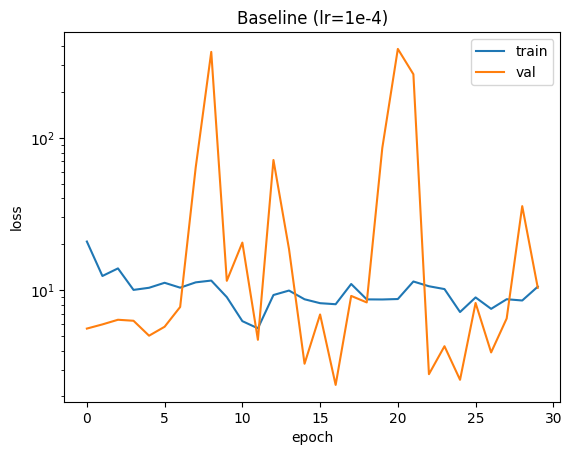

In [24]:
# ---- Step 13: Penn-Fudan baseline training ----
torch.manual_seed(SEED)
model = YOLOv1(S, B, C).cuda()
train_hist, val_hist = train(model, train_loader, val_loader, 'pf_baseline',
                             epochs=30, lr=1e-4, S=S, B=B, C=C)

plt.plot(train_hist, label='train')
plt.plot(val_hist, label='val')
plt.yscale('log')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.title('Baseline (lr=1e-4)')
plt.show()

In [25]:
# ---- Step 14: Penn-Fudan mAP@0.5 aur speed ----
model.load_state_dict(torch.load(f'{CKPT_DIR}/pf_baseline_best.pt')['model'])

for split_name, ds in [('val', val_set), ('test', test_set)]:
    res, ms = evaluate(model, ds, S, B, C)
    print(f"{split_name}: mAP@0.5 = {res['map'].item():.3f}")
print("Speed:", round(ms, 1), "ms/image | FPS ~", round(1000 / ms))
print("Parameters:", count(model))
# is test mAP ko Hassaan ke Ultralytics result (~0.974) ke sath compare karo

val: mAP@0.5 = 0.164
test: mAP@0.5 = 0.114
Speed: 6.6 ms/image | FPS ~ 151
Parameters: 243179867


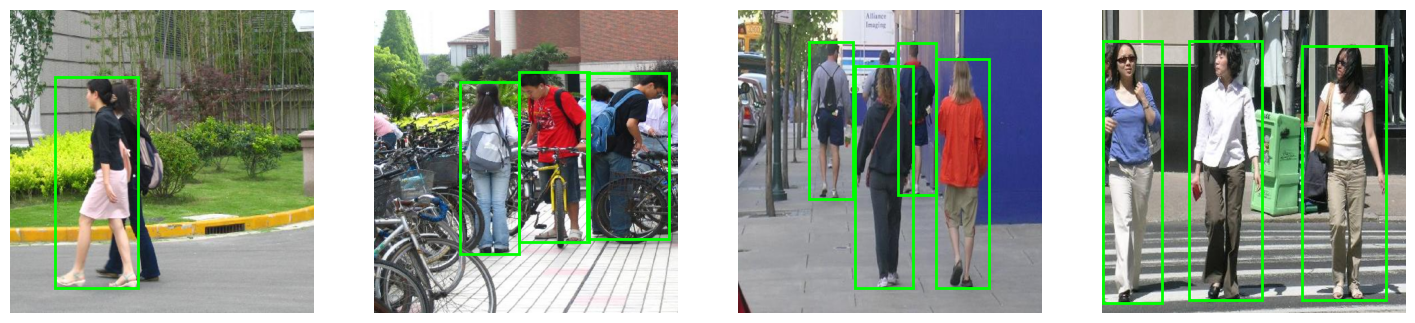

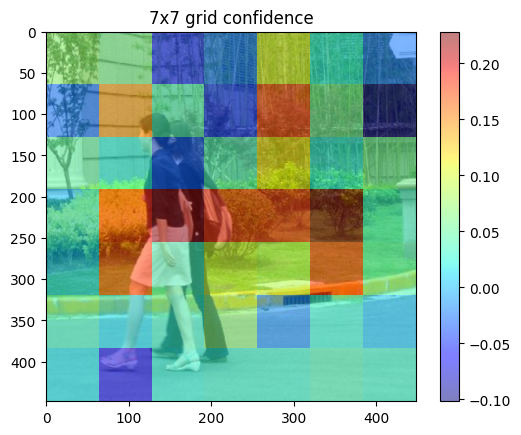

In [26]:
# ---- Step 15: predictions dekho (green = asli, red = model) ----
model.eval()
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, i in zip(axes, [0, 5, 10, 15]):
    x = test_set.image(i)
    with torch.no_grad():
        out = model(x.unsqueeze(0).cuda())[0]
    boxes, scores, labels = detect(out, S, B, C, conf_thr=0.3)
    ax.imshow(x.permute(1, 2, 0))
    for b in test_set.ground_truth(i)[0] * IMG_SIZE:
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1],
                     linewidth=2, edgecolor='lime', facecolor='none'))
    for b in boxes * IMG_SIZE:
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1],
                     linewidth=2, edgecolor='red', facecolor='none', linestyle='--'))
    ax.axis('off')
plt.show()

# model ke andar ka view: har cell ka confidence (demo ke liye)
x = test_set.image(0)
with torch.no_grad():
    out = model(x.unsqueeze(0).cuda())[0].float().cpu()
conf = torch.max(out[..., 4], out[..., 9])
plt.imshow(x.permute(1, 2, 0))
plt.imshow(conf.numpy(), extent=(0, IMG_SIZE, IMG_SIZE, 0), alpha=0.5, cmap='jet')
plt.colorbar()
plt.title('7x7 grid confidence')
plt.show()

--- lr = 3e-05
epoch  1/5 | train 24.113 | val 9.871 | 93s
epoch  2/5 | train 10.284 | val 4.370 | 73s
epoch  3/5 | train 8.119 | val 4.852 | 100s
epoch  4/5 | train 7.420 | val 5.011 | 97s
epoch  5/5 | train 7.066 | val 4.929 | 142s
--- lr = 0.0001
epoch  1/5 | train 20.844 | val 5.586 | 206s
epoch  2/5 | train 10.563 | val 5.618 | 220s
epoch  3/5 | train 12.578 | val 5.539 | 350s
epoch  4/5 | train 10.691 | val 5.040 | 127s
epoch  5/5 | train 10.747 | val 6.015 | 59s
--- lr = 0.0003
epoch  1/5 | train 21.908 | val 7.040 | 133s
epoch  2/5 | train 20.969 | val 7.483 | 195s
epoch  3/5 | train 21.379 | val 7.758 | 83s
epoch  4/5 | train 17.594 | val 191.875 | 68s
epoch  5/5 | train 22.493 | val 2092.219 | 66s


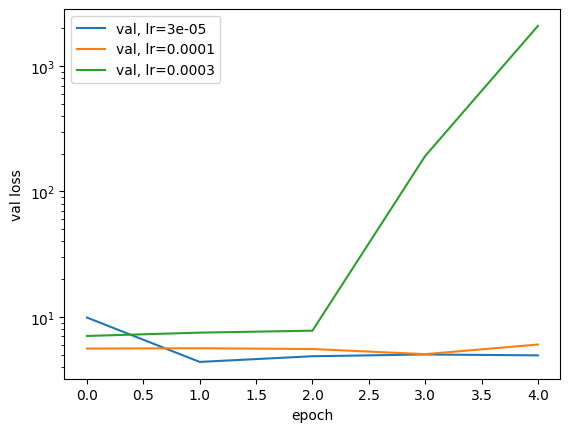

In [27]:
# ---- Step 16: learning rate sweep (3 LR, 5 epochs, same seed) ----
sweep = {}
for lr in [3e-5, 1e-4, 3e-4]:
    print("--- lr =", lr)
    torch.manual_seed(SEED)
    m = YOLOv1(S, B, C).cuda()
    sweep[lr] = train(m, train_loader, val_loader, f'sweep_lr{lr}', epochs=5, lr=lr,
                      freeze_epochs=1, S=S, B=B, C=C, resume=False)

for lr in sweep:
    plt.plot(sweep[lr][1], label=f'val, lr={lr}')
plt.yscale('log')
plt.xlabel('epoch')
plt.ylabel('val loss')
plt.legend()
plt.show()
# jis lr ki val loss sab se kam aur smooth ho wo baseline lr hai

In [28]:
# ---- Step 17: VOC 2007 dataset ----
VOC_CLASSES = ['aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow',
               'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa',
               'train', 'tvmonitor']
VC = 20      # VOC mein 20 classes

class VOCDataset(Dataset):
    def __init__(self, image_set, augment=False, img_size=448, S=7, C=20):
        self.augment, self.img_size, self.S, self.C = augment, img_size, S, C
        # torchvision sirf download aur file list ke liye
        voc = torchvision.datasets.VOCDetection('/content/data', year='2007', image_set=image_set, download=True)
        self.paths = voc.images
        self.boxes, self.labels, self.difficult = [], [], []
        ann_files = voc.targets if hasattr(voc, 'targets') else voc.annotations   # torchvision version ke hisab se
        for ann in ann_files:
            root = ET.parse(ann).getroot()
            W = float(root.find('size/width').text)
            H = float(root.find('size/height').text)
            b, l, d = [], [], []
            for obj in root.findall('object'):
                bb = obj.find('bndbox')
                x1 = float(bb.find('xmin').text) - 1        # VOC boxes 1 se shuru hote hain
                y1 = float(bb.find('ymin').text) - 1
                x2 = float(bb.find('xmax').text)
                y2 = float(bb.find('ymax').text)
                b.append([x1 / W, y1 / H, x2 / W, y2 / H])
                l.append(VOC_CLASSES.index(obj.find('name').text))
                d.append(int(obj.find('difficult').text))
            self.boxes.append(np.array(b, dtype=np.float32))
            self.labels.append(np.array(l))
            self.difficult.append(np.array(d))
        print(image_set, ":", len(self.paths), "images")

    def __len__(self):
        return len(self.paths)

    def image(self, i):
        img = Image.open(self.paths[i]).convert('RGB').resize((self.img_size, self.img_size))
        return torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0

    def ground_truth(self, i):
        return torch.tensor(self.boxes[i]), torch.tensor(self.labels[i]), torch.tensor(self.difficult[i]).bool()

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        boxes = self.boxes[i].copy()
        if self.augment:
            if random.random() < 0.5:                       # horizontal flip
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
                boxes[:, [0, 2]] = 1 - boxes[:, [2, 0]]
            img = ImageEnhance.Brightness(img).enhance(random.uniform(0.7, 1.3))
        img = img.resize((self.img_size, self.img_size))
        x = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
        return x, make_target(boxes, self.labels[i], self.S, self.C)

voc_train = VOCDataset('trainval', augment=True, S=S, C=VC)
voc_test = VOCDataset('test', S=S, C=VC)
voc_loader = DataLoader(voc_train, batch_size=16, shuffle=True, num_workers=2, drop_last=True)

xb, tb = next(iter(voc_loader))
print("Image batch:", xb.shape, "| Target batch:", tb.shape)      # target: (16, 7, 7, 25)

100%|██████████| 460M/460M [00:21<00:00, 21.1MB/s]


trainval : 5011 images


100%|██████████| 451M/451M [00:18<00:00, 24.5MB/s]


test : 4952 images
Image batch: torch.Size([16, 3, 448, 448]) | Target batch: torch.Size([16, 7, 7, 25])


In [29]:
# ---- Step 18: VOC model, sanity, training ----
torch.manual_seed(SEED)
voc_model = YOLOv1(S, B, VC).cuda()
voc_criterion = YOLOLoss(S, B, VC)

# pehle ek batch par check
voc_model.train()
with torch.no_grad():
    pred = voc_model(xb.cuda())
    loss, parts = voc_criterion(pred, tb.cuda())
print("Output:", pred.shape, "| pehla loss:", loss.item(), {k: round(v, 3) for k, v in parts.items()})

#long run (Colab disconnect ho to yehi cell dobara chalao, resume ho jayega)
train(voc_model, voc_loader, None, 'voc_yolov1', epochs=40, lr=1e-4,
      freeze_epochs=3, S=S, B=B, C=VC)

Output: torch.Size([16, 7, 7, 30]) | pehla loss: 29.64790916442871 {'xy': 1.758, 'wh': 2.385, 'obj': 0.347, 'noobj': 5.775, 'cls': 5.697}
epoch  1/40 | train 14.137 | val nan | 103s
epoch  2/40 | train 13.295 | val nan | 127s
epoch  3/40 | train 11.425 | val nan | 121s
epoch  4/40 | train 8.193 | val nan | 127s
epoch  5/40 | train 7.452 | val nan | 124s
epoch  6/40 | train 7.139 | val nan | 128s
epoch  7/40 | train 6.754 | val nan | 122s
epoch  8/40 | train 6.896 | val nan | 123s
epoch  9/40 | train 6.684 | val nan | 133s
epoch 10/40 | train 6.197 | val nan | 128s
epoch 11/40 | train 5.748 | val nan | 125s
epoch 12/40 | train 5.780 | val nan | 122s
epoch 13/40 | train 5.032 | val nan | 122s
epoch 14/40 | train 4.717 | val nan | 125s
epoch 15/40 | train 4.609 | val nan | 127s
epoch 16/40 | train 4.275 | val nan | 132s
epoch 17/40 | train 4.217 | val nan | 131s
epoch 18/40 | train 3.837 | val nan | 127s
epoch 19/40 | train 3.627 | val nan | 127s
epoch 20/40 | train 3.456 | val nan | 131s

([14.137230019980727,
  13.294550987097402,
  11.424728888673142,
  8.193163236490072,
  7.451767749298876,
  7.138733218653133,
  6.754387099902851,
  6.89645189370591,
  6.6843498111152035,
  6.196570269215983,
  5.748286478816511,
  5.779983991251205,
  5.032050957694983,
  4.7169111209174694,
  4.608807366496077,
  4.275190095170237,
  4.216809204972971,
  3.8367453322243006,
  3.627030579807659,
  3.4563116440757775,
  3.2944675493545046,
  3.161686229248778,
  3.0533649144462123,
  2.859938984100049,
  2.811745812717718,
  2.68321209784133,
  2.5900389706364835,
  2.5295903336125822,
  2.4933744364272292,
  2.466430820976964,
  3.7323453205462083,
  2.260917036297222,
  2.213324538244607,
  2.1706539462930476,
  2.081346721694873,
  2.0518674282981944,
  2.2831370413493803,
  2.0894969958847702,
  1.9368732611592205,
  1.914177641891443],
 [nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  nan,
  n

In [30]:
# ---- Step 19: VOC test par mAP@0.5 ----
res, ms = evaluate(voc_model, voc_test, S, B, VC)
print("VOC07 test mAP@0.5:", res['map'].item(), "| paper: 0.634")
print("Speed:", round(ms, 1), "ms/image | FPS ~", round(1000 / ms))

# har class ka AP
for c, a in zip(res['classes'].tolist(), res['map_per_class'].tolist()):
    print(f"{VOC_CLASSES[c]:12s} {a:.3f}")
# note: torchmetrics COCO-style AP use karta hai, VOC07 ke 11-point se thora farq ho sakta hai (report mein likho)

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


VOC07 test mAP@0.5: 0.3329465091228485 | paper: 0.634
Speed: 5.9 ms/image | FPS ~ 170
aeroplane    0.353
bicycle      0.403
bird         0.314
boat         0.132
bottle       0.042
bus          0.428
car          0.449
cat          0.483
chair        0.106
cow          0.231
diningtable  0.317
dog          0.480
horse        0.550
motorbike    0.444
person       0.399
pottedplant  0.088
sheep        0.164
sofa         0.470
train        0.597
tvmonitor    0.210


epoch  1/30 | train 24.113 | val 9.871 | 46s
epoch  2/30 | train 9.861 | val 4.779 | 29s
epoch  3/30 | train 7.338 | val 5.088 | 40s
epoch  4/30 | train 6.828 | val 4.126 | 63s
epoch  5/30 | train 7.154 | val 4.182 | 42s
epoch  6/30 | train 7.396 | val 4.642 | 44s
epoch  7/30 | train 7.706 | val 4.653 | 34s
epoch  8/30 | train 6.948 | val 4.165 | 47s
epoch  9/30 | train 6.270 | val 3.933 | 46s
epoch 10/30 | train 4.972 | val 3.868 | 48s
epoch 11/30 | train 5.156 | val 3.272 | 52s
epoch 12/30 | train 4.771 | val 2.775 | 46s
epoch 13/30 | train 4.710 | val 2.867 | 36s
epoch 14/30 | train 4.413 | val 2.964 | 38s
epoch 15/30 | train 4.479 | val 3.083 | 35s
epoch 16/30 | train 4.170 | val 2.772 | 59s
epoch 17/30 | train 4.302 | val 2.993 | 33s
epoch 18/30 | train 3.622 | val 2.849 | 38s
epoch 19/30 | train 4.136 | val 2.796 | 38s
epoch 20/30 | train 3.527 | val 2.519 | 43s
epoch 21/30 | train 3.441 | val 2.554 | 36s
epoch 22/30 | train 3.246 | val 2.580 | 45s
epoch 23/30 | train 2.904 | val

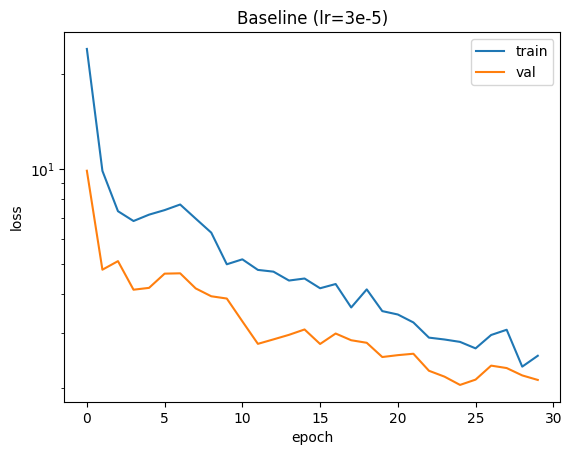

val: mAP@0.5 = 0.333
test: mAP@0.5 = 0.290


In [31]:
# ---- Step 20: Penn-Fudan retrain with lr=3e-5 (sweep ka best) ----
torch.manual_seed(SEED)
model = YOLOv1(S, B, C).cuda()
train_hist, val_hist = train(model, train_loader, val_loader, 'pf_lr3e5',
                             epochs=30, lr=3e-5, S=S, B=B, C=C)

plt.plot(train_hist, label='train'); plt.plot(val_hist, label='val')
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend()
plt.title('Baseline (lr=3e-5)'); plt.show()

model.load_state_dict(torch.load(f'{CKPT_DIR}/pf_lr3e5_best.pt')['model'])
for split_name, ds in [('val', val_set), ('test', test_set)]:
    res, ms = evaluate(model, ds, S, B, C)
    print(f"{split_name}: mAP@0.5 = {res['map'].item():.3f}")

In [32]:
plt.savefig('loss_lr3e5_aug.png', dpi=150, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [34]:
# ---- Step 21a: augmentation ON ----
train_set_aug = PennFudanDataset(ROOT, list(man[man.split == 'train'].filename),
                                 augment=True, S=S, C=C)
train_loader_aug = DataLoader(train_set_aug, batch_size=8, shuffle=True)
print("Aug train images:", len(train_set_aug))

Aug train images: 119


In [57]:
import gc, torch

for name in ['model', 'voc_model', 'm', 'model_aug', 'pred', 'loss', 'xb', 'tb']:
    globals().pop(name, None)

gc.collect()
torch.cuda.empty_cache()
print("Free GPU memory (GB):", torch.cuda.mem_get_info()[0] / 1e9)

Free GPU memory (GB): 8.822521856


In [58]:
import os
for f in ['pf_lr3e5_aug_last.pt', 'pf_lr3e5_aug_best.pt']:
    p = f'{CKPT_DIR}/{f}'
    if os.path.exists(p):
        os.remove(p)
        print("removed:", f)

epoch  1/30 | train 26.228 | val 11.484 | 31s
epoch  2/30 | train 11.298 | val 4.713 | 36s
epoch  3/30 | train 7.735 | val 4.819 | 23s
epoch  4/30 | train 7.860 | val 4.848 | 40s
epoch  5/30 | train 7.976 | val 3.746 | 53s
epoch  6/30 | train 7.054 | val 3.702 | 34s
epoch  7/30 | train 7.601 | val 3.763 | 26s
epoch  8/30 | train 6.328 | val 3.159 | 45s
epoch  9/30 | train 5.836 | val 3.229 | 26s
epoch 10/30 | train 6.037 | val 3.528 | 32s
epoch 11/30 | train 5.174 | val 3.523 | 29s
epoch 12/30 | train 4.811 | val 3.139 | 36s
epoch 13/30 | train 5.138 | val 2.631 | 33s
epoch 14/30 | train 4.739 | val 2.286 | 35s
epoch 15/30 | train 4.472 | val 2.706 | 33s
epoch 16/30 | train 4.717 | val 2.401 | 30s
epoch 17/30 | train 4.507 | val 2.542 | 47s
epoch 18/30 | train 4.248 | val 2.622 | 27s
epoch 19/30 | train 4.263 | val 2.593 | 34s
epoch 20/30 | train 3.944 | val 2.411 | 24s
epoch 21/30 | train 4.172 | val 2.428 | 27s
epoch 22/30 | train 3.987 | val 2.377 | 25s
epoch 23/30 | train 3.728 | v

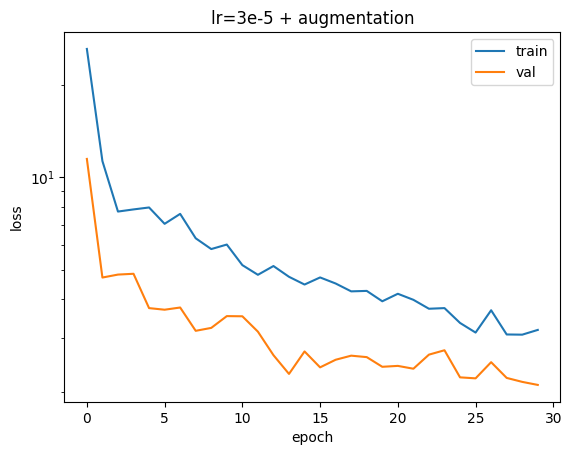

val: mAP@0.5 = 0.360
test: mAP@0.5 = 0.324


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:
# ---- Step 21b: Penn-Fudan lr=3e-5 WITH augmentation ----
torch.manual_seed(SEED)
model_aug = YOLOv1(S, B, C).cuda()
train_hist_aug, val_hist_aug = train(model_aug, train_loader_aug, val_loader, 'pf_lr3e5_aug',
                                     epochs=30, lr=3e-5, S=S, B=B, C=C)

# plot
plt.plot(train_hist_aug, label='train')
plt.plot(val_hist_aug, label='val')
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend()
plt.title('lr=3e-5 + augmentation')
plt.savefig('loss_lr3e5_aug.png', dpi=150, bbox_inches='tight')
plt.show()

# mAP
model_aug.load_state_dict(torch.load(f'{CKPT_DIR}/pf_lr3e5_aug_best.pt')['model'])
for split_name, ds in [('val', val_set), ('test', test_set)]:
    res, ms = evaluate(model_aug, ds, S, B, C)
    print(f"{split_name}: mAP@0.5 = {res['map'].item():.3f}")

# plot download
from google.colab import files
files.download('loss_lr3e5_aug.png')